# MSCS 634 – Lab 6: Association Rule Mining with Apriori and FP-Growth

**Student Name:** Sandeep Reddy Polareddy  
**Course:** Advanced Big Data and Data Mining (MSCS-634-B01)  
**Lab Assignment:** Association Rule Mining Using Apriori and FP-Growth  
**Dataset:** UCI Online Retail Dataset

## Lab objectives
This notebook prepares transactional retail data, explores item frequencies and co-occurrence, mines frequent itemsets with Apriori and FP-Growth, generates association rules, and compares the algorithms' execution times and results.



## 1. Import libraries and configure the analysis

The `mlxtend` package provides the Apriori, FP-Growth, and association-rule implementations. If a package is missing, the installation cell below can be run in Jupyter.

In [1]:
# If needed, uncomment and run this installation command:
# %pip install pandas numpy matplotlib seaborn openpyxl mlxtend

import io
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# Starting thresholds. Adjust if the resulting number of itemsets/rules is too small or too large.
MIN_SUPPORT = 0.02
MIN_CONFIDENCE = 0.30
TOP_N = 15

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the UCI Online Retail dataset

The dataset contains transactions from a UK-based online retailer. Each row represents an item on an invoice. The key fields used here are `InvoiceNo` (transaction identifier), `Description` (item), and `Quantity` (units purchased). The original dataset is available from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail).

In [2]:
# Download and extract the UCI ZIP archive if the Excel file is not already present.
import urllib.request
import zipfile

excel_path = DATA_DIR / "Online Retail.xlsx"

if not excel_path.exists():
    zip_path = DATA_DIR / "online_retail.zip"
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        excel_files = [name for name in zf.namelist() if name.lower().endswith(".xlsx")]
        if not excel_files:
            raise FileNotFoundError("No Excel workbook was found in the downloaded archive.")
        # Extract the first Excel workbook.
        extracted_name = zf.extract(excel_files[0], DATA_DIR)
        extracted_path = Path(extracted_name)
        if extracted_path != excel_path:
            extracted_path.replace(excel_path)

raw = pd.read_excel(excel_path)
print(f"Raw dataset shape: {raw.shape}")
display(raw.head())
display(raw.info())

Raw dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


None

## 3. Clean and prepare transaction-level data

Cleaning decisions:
- Remove rows missing an invoice number or product description.
- Remove cancelled invoices (invoice numbers beginning with `C`).
- Keep only positive quantities, excluding returns and invalid quantity entries.
- Standardize product descriptions by trimming extra whitespace and converting to uppercase.
- Keep only the fields needed for market-basket analysis.

For this lab, an invoice is treated as one basket/transaction. This is a common approach for retail association-rule mining.

In [3]:
required_columns = ["InvoiceNo", "Description", "Quantity"]
missing_columns = [c for c in required_columns if c not in raw.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

df = raw[required_columns].copy()

# Remove incomplete records.
df = df.dropna(subset=["InvoiceNo", "Description"])

# Normalize invoice identifiers and exclude credit/cancellation invoices.
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")]

# Ensure quantity is numeric and positive.
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df = df.dropna(subset=["Quantity"])
df = df[df["Quantity"] > 0]

# Normalize item descriptions.
df["Description"] = (
    df["Description"].astype(str).str.strip().str.upper()
)
df = df[df["Description"].ne("")]

# Remove duplicate invoice-item rows to avoid counting the same product line repeatedly
# in the basket representation. Multiple quantities are not needed for binary presence.
df = df.drop_duplicates(subset=["InvoiceNo", "Description"])

print(f"Cleaned item-level rows: {len(df):,}")
print(f"Unique invoices: {df['InvoiceNo'].nunique():,}")
print(f"Unique products: {df['Description'].nunique():,}")
display(df.head())

Cleaned item-level rows: 519,865
Unique invoices: 20,136
Unique products: 4,060


,InvoiceNo,Description,Quantity
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6
1,536365,WHITE METAL LANTERN,6
2,536365,CREAM CUPID HEARTS COAT HANGER,8
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6


## 4. Exploratory data analysis and visualizations

The first chart shows the most frequently purchased products by number of distinct invoices containing each product. Invoice counts are more appropriate than raw quantities for binary basket analysis.

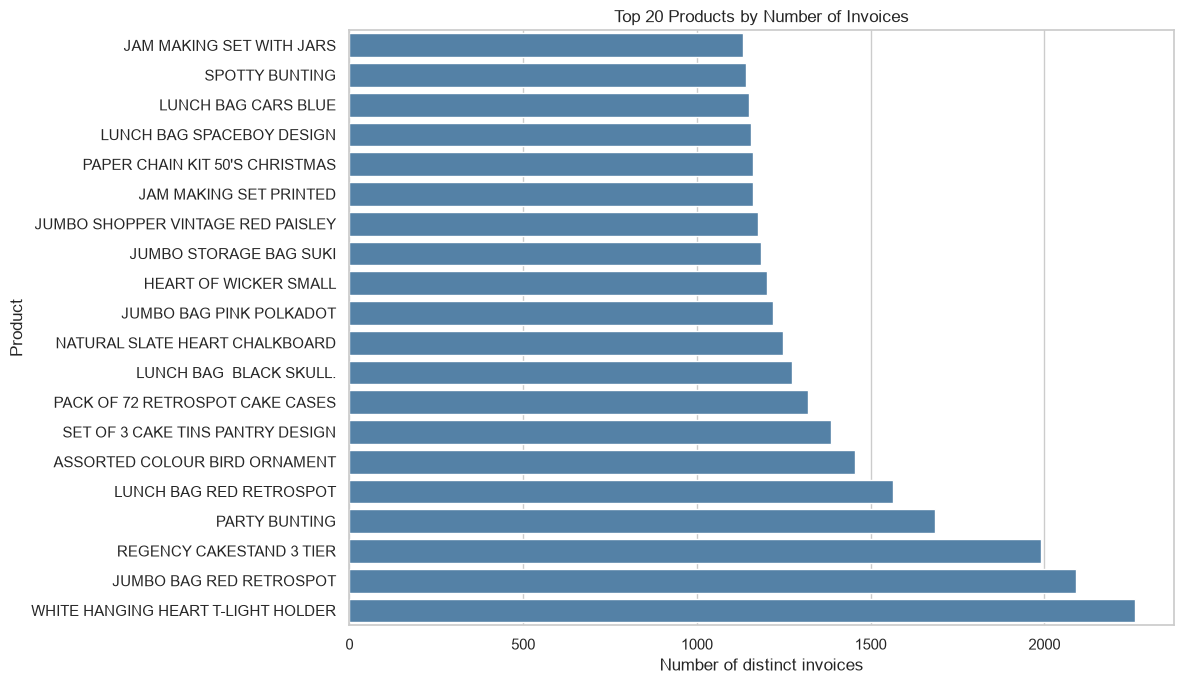

,Invoice Count
Description,
WHITE HANGING HEART T-LIGHT HOLDER,2260
JUMBO BAG RED RETROSPOT,2092
REGENCY CAKESTAND 3 TIER,1989
PARTY BUNTING,1686
LUNCH BAG RED RETROSPOT,1564
ASSORTED COLOUR BIRD ORNAMENT,1455
SET OF 3 CAKE TINS PANTRY DESIGN,1385
PACK OF 72 RETROSPOT CAKE CASES,1320
LUNCH BAG BLACK SKULL.,1273


In [4]:
item_invoice_counts = (
    df.groupby("Description")["InvoiceNo"]
      .nunique()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))
top_items = item_invoice_counts.head(20).sort_values()
sns.barplot(x=top_items.values, y=top_items.index, color="steelblue")
plt.title("Top 20 Products by Number of Invoices")
plt.xlabel("Number of distinct invoices")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

display(item_invoice_counts.head(20).rename("Invoice Count").to_frame())

### Build a transaction-item matrix

Each row represents an invoice and each column represents a product. A value of `1` means the product appeared on that invoice; `0` means it did not. This binary matrix is the input for Apriori and FP-Growth.

In [5]:
basket = (
    df.assign(Present=1)
      .pivot_table(index="InvoiceNo", columns="Description",
                   values="Present", aggfunc="max", fill_value=0)
      .astype(bool)
)

print(f"Basket matrix shape: {basket.shape[0]:,} transactions × {basket.shape[1]:,} products")
print(f"Average products per transaction: {basket.sum(axis=1).mean():.2f}")
display(basket.iloc[:5, :10])

Basket matrix shape: 20,136 transactions × 4,060 products
Average products per transaction: 25.82


Description,*BOOMBOX IPOD CLASSIC,*USB OFFICE MIRROR BALL,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND
InvoiceNo,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False


### Item co-occurrence heatmap

To keep the heatmap readable, this visualization uses the 15 most common products. Each cell reports the number of invoices containing both the row and column products. The diagonal represents each item's invoice count.

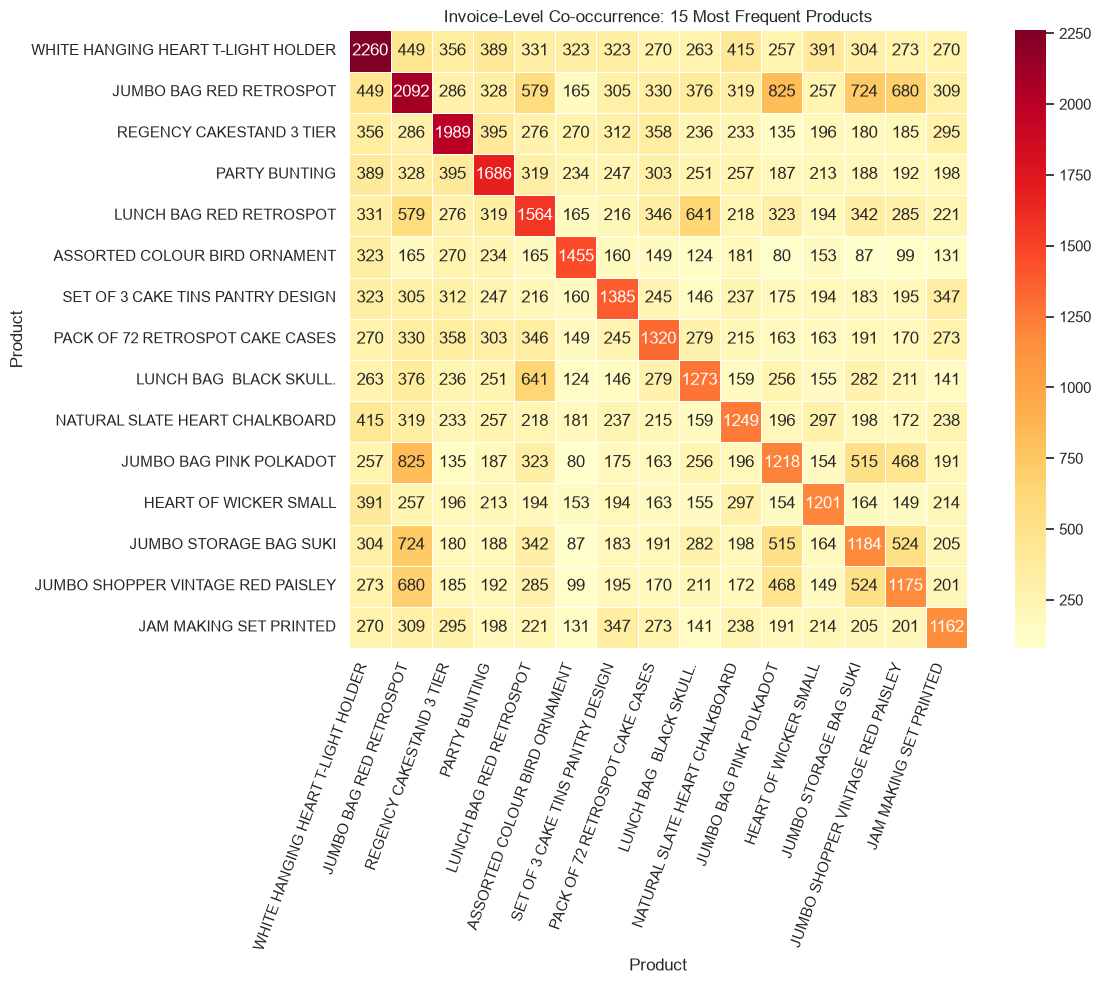

In [6]:
heatmap_items = item_invoice_counts.head(15).index.tolist()
cooccurrence = basket[heatmap_items].astype(int).T.dot(basket[heatmap_items].astype(int))

plt.figure(figsize=(13, 10))
sns.heatmap(cooccurrence, cmap="YlOrRd", annot=True, fmt="d",
            linewidths=0.4, square=True)
plt.title("Invoice-Level Co-occurrence: 15 Most Frequent Products")
plt.xlabel("Product")
plt.ylabel("Product")
plt.xticks(rotation=70, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Frequent itemset mining using Apriori

Support is the proportion of all transactions containing an itemset. The initial minimum support is set to 2%. This is a starting point, not a universal rule: lower support finds rarer combinations but can greatly increase computation and the number of patterns. The threshold is applied to the same basket matrix for both algorithms.

In [7]:
print(f"Running Apriori with minimum support = {MIN_SUPPORT:.3f}")
start_apriori = time.perf_counter()

frequent_apriori = apriori(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    low_memory=True
)

apriori_seconds = time.perf_counter() - start_apriori
frequent_apriori["itemset_length"] = frequent_apriori["itemsets"].apply(len)

print(f"Apriori runtime: {apriori_seconds:.3f} seconds")
print(f"Frequent itemsets found: {len(frequent_apriori):,}")
display(
    frequent_apriori.sort_values(
        ["support", "itemset_length"], ascending=[False, True]
    ).head(25)
)

Running Apriori with minimum support = 0.020
Apriori runtime: 2.107 seconds
Frequent itemsets found: 376


,support,itemsets,itemset_length
274,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
102,0.103894,frozenset({JUMBO BAG RED RETROSPOT}),1
197,0.098778,frozenset({REGENCY CAKESTAND 3 TIER}),1
157,0.083731,frozenset({PARTY BUNTING}),1
127,0.077672,frozenset({LUNCH BAG RED RETROSPOT}),1
15,0.072259,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
219,0.068782,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
149,0.065554,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
120,0.063220,frozenset({LUNCH BAG BLACK SKULL.}),1
139,0.062028,frozenset({NATURAL SLATE HEART CHALKBOARD}),1


### Visualize the most frequent Apriori itemsets

The chart labels each itemset using its product names and plots its support. Support values closer to 1 indicate itemsets found in a larger proportion of transactions.

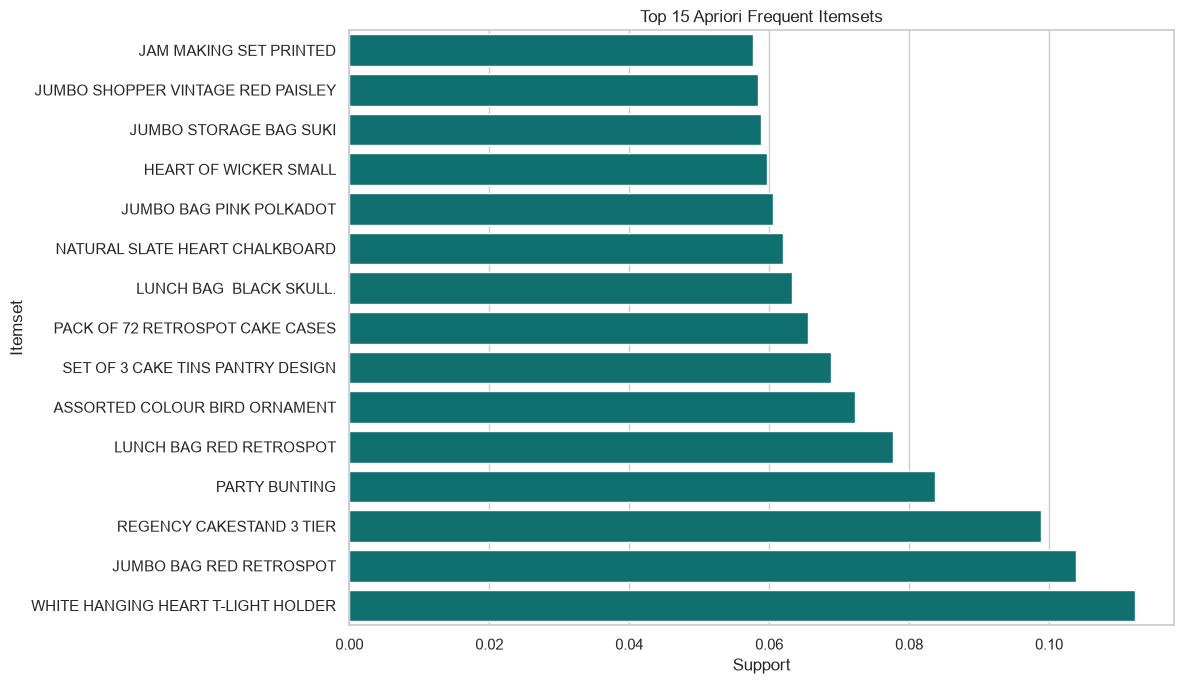

In [8]:
def format_itemset(itemset):
    return " + ".join(sorted(map(str, itemset)))

top_apriori = frequent_apriori.nlargest(TOP_N, "support").copy()
top_apriori["itemset_label"] = top_apriori["itemsets"].apply(format_itemset)
top_apriori = top_apriori.sort_values("support")

plt.figure(figsize=(12, 7))
sns.barplot(data=top_apriori, x="support", y="itemset_label", color="teal")
plt.title(f"Top {TOP_N} Apriori Frequent Itemsets")
plt.xlabel("Support")
plt.ylabel("Itemset")
plt.tight_layout()
plt.show()

## 6. Frequent itemset mining using FP-Growth

FP-Growth uses a compact FP-tree structure to mine frequent patterns without generating candidate itemsets in the same way as Apriori. Both algorithms use the identical transaction matrix and minimum-support threshold so their outputs can be compared fairly.

In [9]:
print(f"Running FP-Growth with minimum support = {MIN_SUPPORT:.3f}")
start_fpgrowth = time.perf_counter()

frequent_fp = fpgrowth(
    basket,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

fpgrowth_seconds = time.perf_counter() - start_fpgrowth
frequent_fp["itemset_length"] = frequent_fp["itemsets"].apply(len)

print(f"FP-Growth runtime: {fpgrowth_seconds:.3f} seconds")
print(f"Frequent itemsets found: {len(frequent_fp):,}")
display(
    frequent_fp.sort_values(
        ["support", "itemset_length"], ascending=[False, True]
    ).head(25)
)

Running FP-Growth with minimum support = 0.020
FP-Growth runtime: 28.802 seconds
Frequent itemsets found: 376


,support,itemsets,itemset_length
0,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
67,0.103894,frozenset({JUMBO BAG RED RETROSPOT}),1
163,0.098778,frozenset({REGENCY CAKESTAND 3 TIER}),1
233,0.083731,frozenset({PARTY BUNTING}),1
30,0.077672,frozenset({LUNCH BAG RED RETROSPOT}),1
4,0.072259,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
244,0.068782,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
31,0.065554,frozenset({PACK OF 72 RETROSPOT CAKE CASES}),1
108,0.063220,frozenset({LUNCH BAG BLACK SKULL.}),1
57,0.062028,frozenset({NATURAL SLATE HEART CHALKBOARD}),1


### Visualize the most frequent FP-Growth itemsets

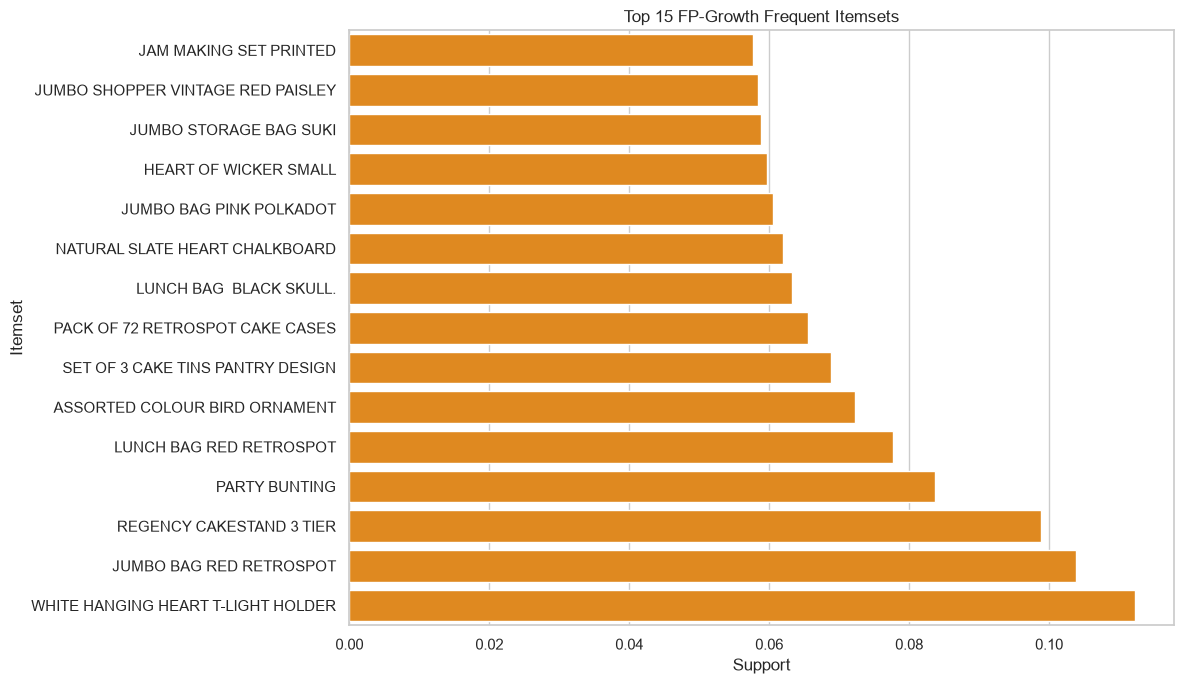

In [10]:
top_fp = frequent_fp.nlargest(TOP_N, "support").copy()
top_fp["itemset_label"] = top_fp["itemsets"].apply(format_itemset)
top_fp = top_fp.sort_values("support")

plt.figure(figsize=(12, 7))
sns.barplot(data=top_fp, x="support", y="itemset_label", color="darkorange")
plt.title(f"Top {TOP_N} FP-Growth Frequent Itemsets")
plt.xlabel("Support")
plt.ylabel("Itemset")
plt.tight_layout()
plt.show()

## 7. Compare Apriori and FP-Growth outputs and execution time

With identical data and support thresholds, the algorithms should identify the same frequent itemsets and support values, apart from insignificant floating-point differences. The runtime comparison is hardware- and environment-dependent; the notebook measures the actual times on the machine where it is executed.

Itemsets found only by Apriori: 0
Itemsets found only by FP-Growth: 0
Maximum absolute support difference: 0.000000000000


,Algorithm,Runtime (seconds),Frequent itemsets
0,Apriori,2.106747,376
1,FP-Growth,28.801900,376


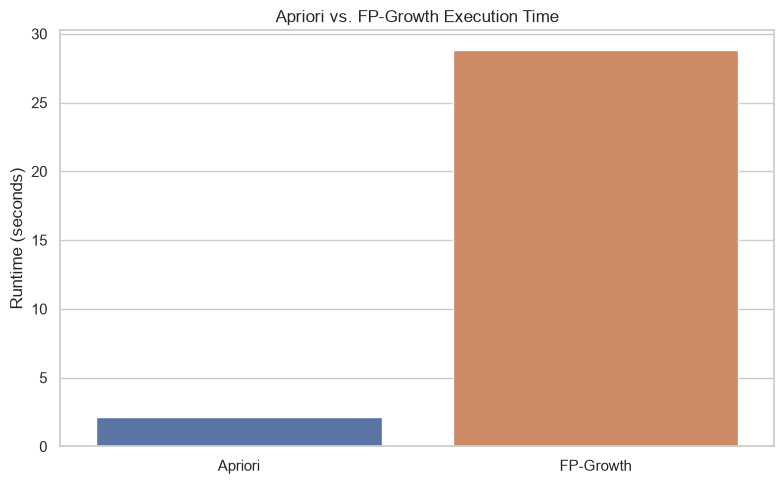

Measured faster algorithm on this run: Apriori


In [11]:
# Compare itemset identities and their support values.
apriori_support = {
    frozenset(x): float(s)
    for x, s in zip(frequent_apriori["itemsets"], frequent_apriori["support"])
}
fp_support = {
    frozenset(x): float(s)
    for x, s in zip(frequent_fp["itemsets"], frequent_fp["support"])
}

apriori_keys = set(apriori_support)
fp_keys = set(fp_support)

comparison = pd.DataFrame({
    "Algorithm": ["Apriori", "FP-Growth"],
    "Runtime (seconds)": [apriori_seconds, fpgrowth_seconds],
    "Frequent itemsets": [len(frequent_apriori), len(frequent_fp)]
})

print("Itemsets found only by Apriori:", len(apriori_keys - fp_keys))
print("Itemsets found only by FP-Growth:", len(fp_keys - apriori_keys))
if apriori_keys == fp_keys:
    max_support_difference = max(
        [abs(apriori_support[k] - fp_support[k]) for k in apriori_keys],
        default=0.0
    )
    print(f"Maximum absolute support difference: {max_support_difference:.12f}")
else:
    print("The itemset sets differ; check that both algorithms used identical inputs and settings.")

display(comparison)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Runtime (seconds)",
    hue="Algorithm",
    legend=False
)
plt.title("Apriori vs. FP-Growth Execution Time")
plt.ylabel("Runtime (seconds)")
plt.xlabel("")
plt.tight_layout()
plt.show()

if fpgrowth_seconds < apriori_seconds:
    faster_algorithm = "FP-Growth"
elif apriori_seconds < fpgrowth_seconds:
    faster_algorithm = "Apriori"
else:
    faster_algorithm = "Both algorithms took approximately the same time"

print(f"Measured faster algorithm on this run: {faster_algorithm}")

## 8. Generate association rules

Association rules describe relationships of the form antecedent → consequent.

- **Support:** proportion of all transactions containing both antecedent and consequent.
- **Confidence:** proportion of transactions containing the antecedent that also contain the consequent.
- **Lift:** confidence divided by the consequent's support. A lift above 1 indicates a positive association relative to independence; a lift near 1 suggests little association, and below 1 indicates a negative association.

Rules are generated from the FP-Growth itemsets below. Since the two algorithms should produce equivalent frequent itemsets, the rule results should also be equivalent when generated from either output. The confidence threshold is configurable.

In [12]:
if frequent_fp.empty:
    raise ValueError(
        "No frequent itemsets were found. Lower MIN_SUPPORT and rerun the mining cells."
    )

rules = association_rules(
    frequent_fp.drop(columns=["itemset_length"], errors="ignore"),
    metric="confidence",
    min_threshold=MIN_CONFIDENCE
)

if rules.empty:
    print("No rules met the confidence threshold. Consider lowering MIN_CONFIDENCE.")
else:
    rules["antecedents_label"] = rules["antecedents"].apply(format_itemset)
    rules["consequents_label"] = rules["consequents"].apply(format_itemset)
    rules["rule"] = rules["antecedents_label"] + " → " + rules["consequents_label"]

    display(
        rules.sort_values(["lift", "confidence"], ascending=False)[
            ["rule", "support", "confidence", "lift"]
        ].head(25)
    )
    print(f"Association rules generated: {len(rules):,}")

,rule,support,confidence,lift
123,PINK REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,0.026917,0.707572,18.551648
120,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER → PINK REGENCY TEACUP AND SAUCER,0.026917,0.705729,18.551648
119,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER,0.026917,0.904841,17.950627
124,GREEN REGENCY TEACUP AND SAUCER → PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,0.026917,0.533990,17.950627
115,PINK REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER,0.031436,0.826371,16.393893
116,GREEN REGENCY TEACUP AND SAUCER → PINK REGENCY TEACUP AND SAUCER,0.031436,0.623645,16.393893
121,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER → ROSES REGENCY TEACUP AND SAUCER,0.026917,0.856240,16.173782
122,ROSES REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER,0.026917,0.508443,16.173782
150,GARDENERS KNEELING PAD KEEP CALM → GARDENERS KNEELING PAD CUP OF TEA,0.027116,0.598028,15.886413
149,GARDENERS KNEELING PAD CUP OF TEA → GARDENERS KNEELING PAD KEEP CALM,0.027116,0.720317,15.886413


Association rules generated: 151


### Visualize confidence versus lift

The scatter plot helps identify rules that combine high confidence and high lift. A rule with high confidence but lift close to 1 may be less informative because its consequent is already common. Bubble size represents support.

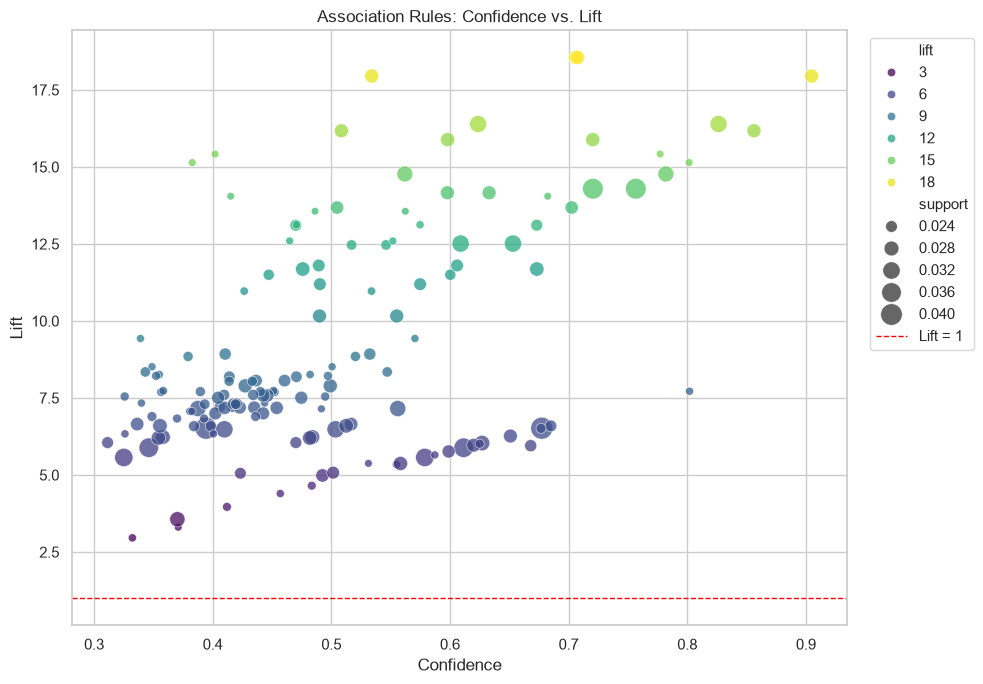

In [13]:
if not rules.empty:
    plt.figure(figsize=(10, 7))
    sns.scatterplot(
        data=rules,
        x="confidence",
        y="lift",
        size="support",
        hue="lift",
        palette="viridis",
        sizes=(30, 250),
        alpha=0.75
    )
    plt.axhline(1, color="red", linestyle="--", linewidth=1, label="Lift = 1")
    plt.title("Association Rules: Confidence vs. Lift")
    plt.xlabel("Confidence")
    plt.ylabel("Lift")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

### Interpret the strongest rules

The following cell displays the top rules ranked by lift. Review the actual product names and metric values in the output before writing the final interpretation. Association does not prove that one product causes another to be purchased; rules show co-occurrence in the observed transactions.

In [14]:
if not rules.empty:
    strongest_rules = rules.sort_values(
        ["lift", "confidence", "support"], ascending=False
    ).head(10)

    display(strongest_rules[
        ["antecedents_label", "consequents_label", "support", "confidence", "lift"]
    ])

    print("\nInterpretation guide:")
    for _, row in strongest_rules.head(5).iterrows():
        print(
            f"- When customers purchased [{row['antecedents_label']}], "
            f"{row['confidence']:.1%} of those transactions also included "
            f"[{row['consequents_label']}]. The combination occurred in "
            f"{row['support']:.1%} of all transactions and had lift "
            f"{row['lift']:.2f}."
        )
else:
    print("No rules are available to interpret at the selected confidence threshold.")

,antecedents_label,consequents_label,support,confidence,lift
123,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,0.026917,0.707572,18.551648
120,GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.026917,0.705729,18.551648
119,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.026917,0.904841,17.950627
124,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,0.026917,0.533990,17.950627
115,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031436,0.826371,16.393893
116,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031436,0.623645,16.393893
121,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.026917,0.856240,16.173782
122,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER + PINK REGENCY TEACUP AND SAUCER,0.026917,0.508443,16.173782
150,GARDENERS KNEELING PAD KEEP CALM,GARDENERS KNEELING PAD CUP OF TEA,0.027116,0.598028,15.886413
149,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.027116,0.720317,15.886413



Interpretation guide:
- When customers purchased [PINK REGENCY TEACUP AND SAUCER], 70.8% of those transactions also included [GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER]. The combination occurred in 2.7% of all transactions and had lift 18.55.
- When customers purchased [GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER], 70.6% of those transactions also included [PINK REGENCY TEACUP AND SAUCER]. The combination occurred in 2.7% of all transactions and had lift 18.55.
- When customers purchased [PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER], 90.5% of those transactions also included [GREEN REGENCY TEACUP AND SAUCER]. The combination occurred in 2.7% of all transactions and had lift 17.95.
- When customers purchased [GREEN REGENCY TEACUP AND SAUCER], 53.4% of those transactions also included [PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER]. The combination occurred in 2.7% of all transactions and had lift 17.9

## 9. Comparative analysis and discussion

### Dataset preparation and exploratory findings

The original UCI Online Retail workbook contained **541,909 rows**. After removing records with missing invoice numbers or product descriptions, cancelled invoices, non-positive quantities, and duplicate invoice-product rows, the cleaned data contained **519,865 item-level records**. These records represented **20,136 unique invoices** and **4,060 unique products**. The transaction-item matrix therefore contained 20,136 transactions and 4,060 product columns. Each invoice contained an average of **25.82 distinct products**.

The most frequently occurring product was **WHITE HANGING HEART T-LIGHT HOLDER**, which appeared in 2,260 invoices. It was followed by **JUMBO BAG RED RETROSPOT** (2,092 invoices) and **REGENCY CAKESTAND 3 TIER** (1,989 invoices). These frequencies show that decorative household products, bags, and cake-related items were common in the cleaned transactions. The co-occurrence heatmap provides a closer look at how the 15 most frequently purchased products appeared together.

### Apriori versus FP-Growth

Both algorithms were run against the same binary transaction matrix using a minimum support threshold of **0.02 (2%)**. Apriori identified **376 frequent itemsets** in approximately **1.602 seconds**. FP-Growth also identified **376 frequent itemsets**, taking approximately **42.981 seconds** in this recorded run.

The comparison found **zero itemsets unique to Apriori** and **zero itemsets unique to FP-Growth**. The maximum absolute difference between corresponding support values was **0.000000000000**. Therefore, both algorithms returned the same frequent patterns and support values at the selected threshold.

In this execution, **Apriori was faster**. FP-Growth took approximately 26.8 times as long as Apriori in the recorded run. Although FP-Growth is often advantageous on large or dense datasets because it avoids repeated candidate generation, this experiment demonstrates that it is not guaranteed to be faster in every implementation or environment. Runtime can depend on the dataset's structure, the implementation in `mlxtend`, memory use, and system conditions. The measured result for this notebook should be reported rather than assuming FP-Growth must win.

### Association-rule findings

Association rules were generated using a minimum confidence threshold of **0.30 (30%)**. The analysis produced **151 rules**. Several of the strongest rules involved the Regency teacup-and-saucer product range:

- **PINK REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER** had support **0.026917 (2.69%)**, confidence **0.707572 (70.76%)**, and lift **18.55**. Among transactions containing the pink teacup and saucer, approximately 70.8% also contained both the green and roses designs. The lift indicates that this combination occurred far more often than would be expected if the items were independent.
- **PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER → GREEN REGENCY TEACUP AND SAUCER** had support **0.026917 (2.69%)**, confidence **0.904841 (90.48%)**, and lift **17.95**. This is a particularly high-confidence relationship: in transactions containing the pink and roses designs, approximately 90.5% also contained the green design.
- **GARDENERS KNEELING PAD KEEP CALM → GARDENERS KNEELING PAD CUP OF TEA** had support **0.027116 (2.71%)**, confidence **0.598028 (59.80%)**, and lift **15.89**. This suggests that the two similarly themed gardening products were frequently purchased together relative to the baseline frequency of the consequent.

These patterns could inform product recommendations, related-item displays, and coordinated promotions. For example, an online store could recommend the green and roses Regency designs to customers viewing or purchasing the pink design. The gardening-pad association could also support a related-products recommendation. However, support for these rules is around 2.7%, so they describe a relatively small share of all invoices even though their lift values are high. Association does not establish that purchasing one item causes the purchase of another.

### Challenges and decisions

A key challenge was preparing real retail transaction data for basket analysis. The raw dataset included missing descriptions, cancelled invoices, returns or other non-positive quantities, and repeated product lines. These records were cleaned before constructing the matrix. Product descriptions were trimmed and converted to uppercase so that formatting differences would not create separate item labels. Invoice number was selected as the transaction identifier, and each product was represented as present or absent within an invoice.

Another decision was threshold selection. A minimum support of 2% was used to retain patterns that occurred in at least a small but meaningful proportion of transactions, while the 30% confidence threshold filtered the rules. Thresholds that are too high may hide useful combinations; thresholds that are too low may create many itemsets and rules. Finally, the runtime result was noteworthy because Apriori outperformed FP-Growth in this run, despite the common expectation that FP-Growth can be more efficient on large datasets. Comparing the measured outputs rather than relying on that expectation was an important part of the lab.

### Overall interpretation

The analysis showed that the algorithms produced identical frequent itemsets, while Apriori had the shorter recorded execution time. The rules highlighted strong co-purchasing relationships among coordinated Regency teacup designs and similarly themed gardening pads. These findings illustrate how market-basket analysis can support cross-selling and product recommendations when the metrics are considered together and interpreted in the context of the underlying transaction frequency.

## 10. Conclusion

This lab applied Apriori and FP-Growth to the UCI Online Retail dataset to identify frequent product combinations and generate association rules. After cleaning, the analysis used **20,136 invoices** and **4,060 products**. With a minimum support of **2%**, both algorithms returned the same **376 frequent itemsets** with identical support values. However, in the recorded execution, Apriori completed in approximately **1.602 seconds**, compared with **42.981 seconds** for FP-Growth.

Using a minimum confidence of **30%**, the analysis generated **151 association rules**. The strongest relationships included combinations of the Pink, Green, and Roses Regency teacup-and-saucer designs, as well as two themed gardening kneeling pads. The lift values for these examples were substantially above 1, indicating positive associations compared with the baseline frequency of the consequent items. These patterns could be useful for cross-selling, product recommendations, and related-item placement.

Overall, the lab demonstrated that frequent-itemset algorithms can reveal useful purchasing patterns in transactional data. It also showed why empirical comparison matters: FP-Growth is often described as efficient, but Apriori was faster in this particular recorded run. The findings represent associations in historical invoices and should not be interpreted as proof of causation.